# 04 — Fusion and operational evaluation

**Purpose.** Show that fusing views can amplify recording sensitivity, and that permissive event
matching can overstate detection when a few long alarms cover many actions.

**Inputs**  `results/paper_tables/{physical_anchor_comparison,fusion_conditioning_results,
event_matching_sensitivity,operating_curve_points}.csv`.

**Outputs**  `results/regenerated/fusion_operational_summary.csv`.


In [1]:
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive; drive.mount('/content/drive')
    os.environ.setdefault('PROVICS_ROOT', '/content/drive/MyDrive/provics-recording-aware-evaluation')
else:
    os.environ.setdefault('PROVICS_ROOT', str(Path.cwd().parent))
sys.path.insert(0, os.environ['PROVICS_ROOT'])
from src.utils.paths import project_root
ROOT = project_root(); print('Project folder:', ROOT.name)

# Render compact, readable tables below each cell.
from IPython.display import display
import pandas as pd
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)


Project folder: code


In [2]:
from src.features.fusion import ALL_VIEWS, CYBER_VIEWS
from src.evaluation.replay import load_settings
fusion = load_settings()['fusion']
print('cyber-only sum-z :', fusion['cyber_only_sum_z'])
print('all-view sum-z   :', fusion['all_view_sum_z'])
print('late-OR / max-z  :', fusion['late_or_max_z'])
print('CCA residual     :', fusion['cca_residual'])
print('label use        :', fusion['label_use'])


cyber-only sum-z : sum of standardized scores over M1, M2, M3
all-view sum-z   : sum of standardized scores over M1, M2, M3, M4
late-OR / max-z  : maximum standardized score across the four modalities
CCA residual     : one-component CCA residual between cyber and physical scores
label use        : primary detectors and fusion methods do not use attack labels as a training target


In [3]:
# Fusing the three cyber views produces a LARGER gap than any of them alone at 5, 10 and 30 s.
import pandas as pd
anchor = pd.read_csv(ROOT / 'results/paper_tables/physical_anchor_comparison.csv')
display(anchor[['window_s','cyber_delta_cw','fused_delta_cw','cyber_within_auc',
                'fused_within_auc','cyber_occupancy','fused_occupancy']].round(3))
print()
print('Adding the physical view lowers the gap to about %.2f and raises same-recording AUC,'
      % anchor.fused_delta_cw.mean())
print('but outside-action occupancy rises to %.2f-%.2f. The ranking improves; the alarm cost does not.'
      % (anchor.fused_occupancy.min(), anchor.fused_occupancy.max()))


,window_s,cyber_delta_cw,fused_delta_cw,cyber_within_auc,fused_within_auc,cyber_occupancy,fused_occupancy
0,5,0.540,0.241,0.459,0.759,0.591,0.930
1,10,0.528,0.231,0.471,0.769,0.677,0.934
2,30,0.453,0.228,0.547,0.771,0.660,0.934
3,60,0.390,0.232,0.610,0.768,0.722,0.950



Adding the physical view lowers the gap to about 0.23 and raises same-recording AUC,
but outside-action occupancy rises to 0.93-0.95. The ranking improves; the alarm cost does not.


### Fusion changes both the gap and alarm burden

Both panels come directly from the saved physical-anchor comparison table. A smaller AUC gap does not by itself imply a lower alarm burden.


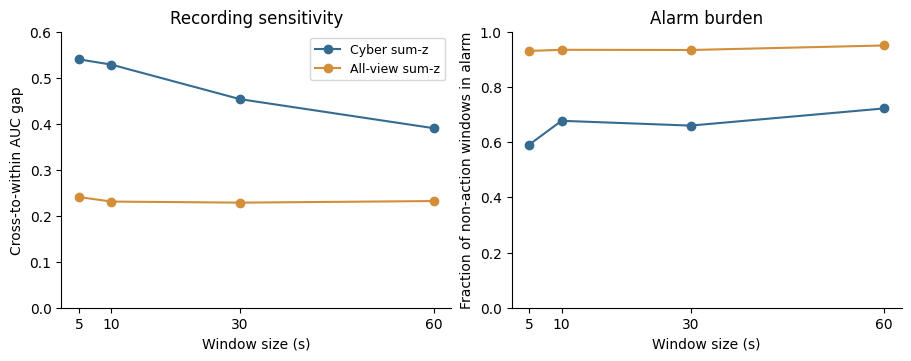

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
for prefix, label, color in [('cyber', 'Cyber sum-z', '#366b91'), ('fused', 'All-view sum-z', '#d28e38')]:
    axes[0].plot(anchor.window_s, anchor[f'{prefix}_delta_cw'], 'o-', label=label, color=color)
    axes[1].plot(anchor.window_s, anchor[f'{prefix}_occupancy'], 'o-', label=label, color=color)
axes[0].set(ylabel='Cross-to-within AUC gap', ylim=(0, 0.6), title='Recording sensitivity')
axes[1].set(ylabel='Fraction of non-action windows in alarm', ylim=(0, 1), title='Alarm burden')
for ax in axes:
    ax.set_xlabel('Window size (s)')
    ax.set_xticks([5, 10, 30, 60])
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=9)
plt.show()
plt.close(fig)

In [5]:
# Not every fusion behaves alike. CCA residual has a small or negative gap but low recall.
families = pd.read_csv(ROOT / 'results/paper_tables/fusion_conditioning_results.csv')
view = families[families.window_s == 60].groupby('family').agg(
    delta_cw=('delta_cw','mean'), within=('within_auc','mean'),
    occupancy=('outside_action_occupancy','mean'), recall=('event_recall','mean')).round(3)
display(view.sort_values('delta_cw'))


,delta_cw,within,occupancy,recall
family,,,,
latent_cca,-0.179,0.677,0.031,0.262
M4,0.155,0.777,0.770,0.800
late_or,0.202,0.797,0.787,0.981
sum_z_fusion,0.232,0.768,0.950,1.000
M2,0.383,0.574,0.199,0.600
cyber_only_fusion,0.390,0.610,0.722,1.000
M3,0.393,0.607,0.917,1.000
M1,0.404,0.568,0.053,0.750


In [6]:
# Event matching. The primary metric is deterministic one-to-one; any-overlap is permissive.
matching = pd.read_csv(ROOT / 'results/paper_tables/event_matching_sensitivity.csv')
at60 = matching[matching.window_s == 60]
recall = at60.groupby(['family','rule']).event_recall.mean().unstack()
display(recall[['one_to_one','post_onset_alert_start','any_overlap']].round(3))
print('\ncolumns: PRIMARY (1:1), post-onset start, SECONDARY permissive (any overlap)')


rule,one_to_one,post_onset_alert_start,any_overlap
family,,,
M1,0.502,0.343,0.689
M2,0.421,0.306,0.636
M3,0.153,0.101,0.963
M4,0.171,0.134,0.844
cyber_only_fusion,0.407,0.211,0.963
late_or,0.197,0.123,0.941
latent_cca,0.134,0.106,0.209
sum_z_fusion,0.123,0.086,0.963



columns: PRIMARY (1:1), post-onset start, SECONDARY permissive (any overlap)


### Event coverage depends on the matching rule

These bars use the same saved alarm results. Any-overlap can credit one long alarm with several events; one-to-one matching limits that credit. No thresholds are changed here.


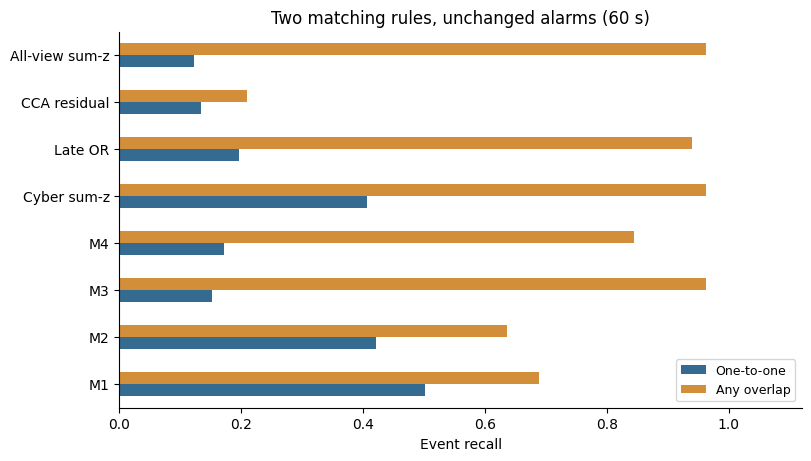

In [7]:
import matplotlib.pyplot as plt
labels = {'cyber_only_fusion': 'Cyber sum-z', 'sum_z_fusion': 'All-view sum-z',
          'late_or': 'Late OR', 'latent_cca': 'CCA residual'}
shown = recall[['one_to_one', 'any_overlap']].rename(index=labels,
    columns={'one_to_one': 'One-to-one', 'any_overlap': 'Any overlap'})
fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
shown.plot.barh(ax=ax, color=['#366b91', '#d28e38'])
ax.set(xlabel='Event recall', ylabel='', xlim=(0, 1.12), title='Two matching rules, unchanged alarms (60 s)')
ax.legend(loc='lower right', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.show()
plt.close(fig)

In [8]:
# Why the two differ so much: episode saturation.
episodes = at60[at60.rule == 'any_overlap'].groupby('family').agg(
    alarm_episodes=('n_alarm_episodes','mean'), matched=('n_matched_episodes','mean'),
    events_per_matched=('events_per_matched_episode','mean'),
    longest_episode_windows=('max_episode_windows','mean')).round(2)
display(episodes)
print('\nA single episode of 227 consecutive 60-s windows is 3.8 hours of continuous alarm.',
      'Under any-overlap it is credited with every action it spans.')

out = ROOT / 'results/regenerated'; out.mkdir(parents=True, exist_ok=True)
view.join(recall[['one_to_one','any_overlap']]).to_csv(out / 'fusion_operational_summary.csv')
print('\nwrote results/regenerated/fusion_operational_summary.csv')


,alarm_episodes,matched,events_per_matched,longest_episode_windows
family,,,,
M1,15.40,4.93,1.57,2.80
M2,10.80,5.27,1.57,32.93
M3,4.20,1.33,7.67,150.27
M4,7.87,1.47,6.31,103.53
cyber_only_fusion,30.93,6.47,3.54,61.47
late_or,14.27,2.53,6.44,135.20
latent_cca,2.93,1.20,1.61,2.07
sum_z_fusion,1.27,1.00,8.33,227.27



A single episode of 227 consecutive 60-s windows is 3.8 hours of continuous alarm. Under any-overlap it is credited with every action it spans.

wrote results/regenerated/fusion_operational_summary.csv


## What this notebook established

- Cyber-only fusion has a larger cross-to-within gap than any single cyber view at 5, 10 and 30 s.
- Adding the physical view reduces the gap to about 0.23 but leaves alarm active in 93-95% of non-action windows.
- Fusion strategies differ: the CCA residual shows a small or negative gap with low recall.
- One-to-one recall of 0.123 against any-overlap 0.963 is explained by one 227-window alarm episode.
